In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle

prop_cycle = plt.rcParams["axes.prop_cycle"]
colors = cycle(prop_cycle.by_key()["color"])

Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data
note how I just call this "d" b/c I assume that I'll later on load a different dataset as "d".  But, you can do whatever you like.

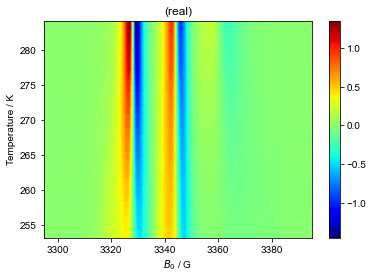

In [2]:
d = find_file("240510_TS_C10_W3S2_run4.DSC", exp_type="francklab_esr/romana")  # w3
# I should be able to do the following without the chunk-auto, but then sort freaks out -- this is a bug-jmf
d = d.chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]
d.reorder("Temperature").sort("Temperature")
d.pcolor()

## Check field ranges for the three lines
Here, take the strategy of storing the ranges in a nested dictionary.
Store two sets of peaks, above and below the temperature.
In general **you need to adjust** these ranges for every dataset.

In [5]:
peak_ranges = {
    "above T": {
        "A": (3320, 3335),
        "B": (3335, 3351),
        "C": (3350.5, 3380),
    },
    "below T": {
        "A": (3318, 3335),
        "B": (3335, 3351),
        "C": (3354, 3375),
    },
}

We define a function to check the peak ranges.  This way, we can re-use it
for different datasets.
It returns the correlation times as an nddata.
This function shouldn't be modified without discussing with JF.

In general I'm going to define a few functions here.
As long as they are working **for the sake of time, you can ignore the contents of the functions for now**

In [6]:
def check_ranges(d, peak_ranges, threshold_T=265):
    # peak_ranges contains keys for the different temperature ranges
    # the values are the dictionaries of peaks at those ranges
    gs = GridSpec(3, 2, hspace=0.6)
    fig = figure()
    for j, (which_T_range, peak_dict) in enumerate(peak_ranges.items()):
        # Here we set the temperature range according to the name
        T_range = (None, threshold_T)
        if which_T_range == "above T":
            T_range = (threshold_T, None)
        # loop over the peak ranges
        for k, (peakname, B_range) in enumerate(peak_dict.items()):
            fig.add_subplot(gs[k, j])
            title(which_T_range + " for peak " + peakname)
            plot(
                d["Temperature":T_range]["$B_0$":B_range]
            )  # peak A above transition

now, I can test the peak ranges above.  If I slice so that the max and min are correct, then the next function should work well.

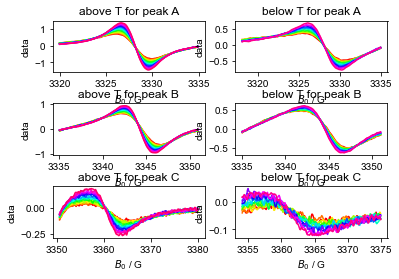

In [7]:
check_ranges(d, peak_ranges)

# Pick the Peaks and Calculate the Correlation times

Now, using the peak ranges we defined above, go ahead and actually determine
the correlation times.
Notice how this takes arguments of your data and the peak ranges, and determines the correlation times

In [8]:
def determine_tau(all_data, peak_ranges):
    correlation_time = {}
    x_counter = 0
    j_counter = 0
    gs = GridSpec(1, 3, hspace=0.6)
    fig = figure(figsize=(10, 20))
    ax_dict = {}  # in place of a normal fig list
    # loop over the temperatures
    for k, this_temp in enumerate(all_data["Temperature"]):
        offset = k * 0.5
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature":this_temp]
        # normalize
        d /= d.max().item()
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 265:
            peak_dict = peak_ranges["above T"]
        else:
            peak_dict = peak_ranges["below T"]
        for j, (peak_name, B_range) in enumerate(peak_dict.items()):
            current_plot = f"slice peak {peak_name}"
            if current_plot not in ax_dict.keys():
                ax_dict[current_plot] = fig.add_subplot(gs[j])
            else:
                plt.sca(ax_dict[current_plot])
            plt.title(current_plot)
            peak = d["$B_0$":B_range]
            plot(peak + offset, c=this_color, alpha=0.5)
            peak = peak.spline_lambda(s_multiplier=1e-2)(
                linspace(*tuple(B_range + (500,)))
            )  # overwrite with a smoothed one
            plot(peak + offset, c=this_color, alpha=0.2)
            max_B0 = (
                peak.C.argmax().item()
            )  # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()[
                "$B_0$"
            ]  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name + "max"] = peak[
                "$B_0$":max_B0
            ].item()  # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name + "min"] = peak["$B_0$":min_B0].item()
            peak_data[
                peak_name + "maxB0"
            ] = max_B0  # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name + "minB0"] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(
                peak_data[peak_name + "maxB0"],
                peak_data[peak_name + "max"] + offset,
                "o",
                c=this_color,
                alpha=0.5,
            )
            plot(
                peak_data[peak_name + "minB0"],
                peak_data[peak_name + "min"] + offset,
                "x",
                c=this_color,
                alpha=0.5,
            )
            # }}}
        current_plot = "stacked"
        if current_plot not in ax_dict.keys():
            fig2 = figure()
            ax_dict[current_plot] = fig2.add_subplot(111)
        else:
            plt.sca(ax_dict[current_plot])
        plot(
            d + x_counter, alpha=0.8, color=this_color
        )  ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval(
            "6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",
            {"sqrt": sqrt},
            peak_data,
        )
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        correlation_time[label_str] = tau_c
        plt.gca().text(
            3370,
            x_counter,
            label_str + f" K\n$\\tau_c={tau_c/1e-9:0.2f}$ ns",
            transform=plt.gca().transData,
            va="bottom",
            ha="left",
            color=this_color,
        )
        x_counter += 1
        # xlim(3375,3550)
        j_counter += 1.2
    current_plot = "stacked"
    plt.sca(ax_dict[current_plot])
    plt.title("")
    plt.ylabel("")
    plt.gca().tick_params(
        left=False,
        bottom=True,
        right=False,
        top=False,
        labelleft=False,
        labelbottom=True,
        labelright=False,
    )
    correlation_time = nddata(
        np.array(list(correlation_time.values())), [-1], ["T"]
    ).setaxis(
        "T", np.array([float(j) for j in correlation_time.keys()])
    )
    return correlation_time

Now, I actually run the function.  Notice how here, I do give it a special variable name, because I want to keep around the correlation times from the different datasets

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

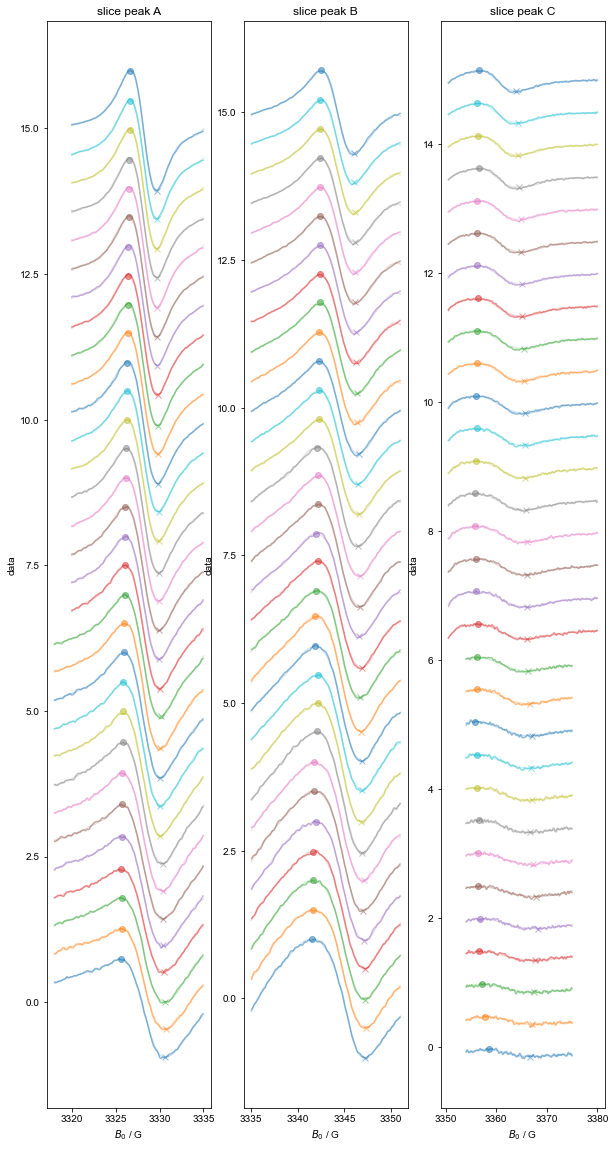

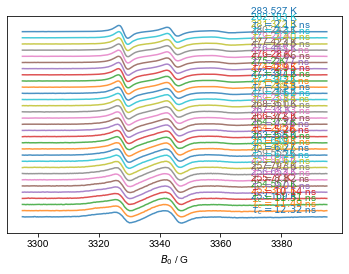

In [9]:
correlation_time_w3 = determine_tau(d, peak_ranges)

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


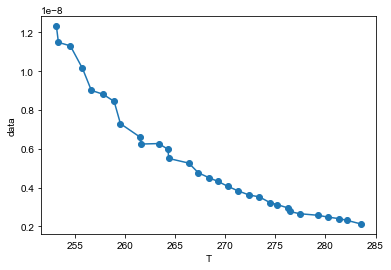

In [10]:
plot(correlation_time_w3,'o-')

this converts to arrhenius **please note I'm using the modified formula from the paper**

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


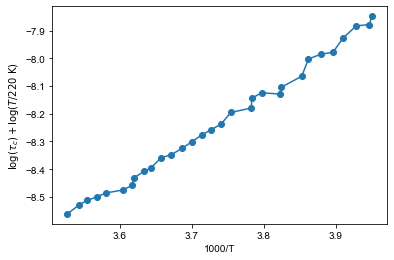

In [11]:
def convert_to_Arrhenius(d):
    d = d.C # make a copy
    d.run(np.log10)
    d += d.fromaxis('T').run(lambda x: np.log10(x/220))
    d['T'] = 1000/d['T']
    d.rename('T','1000/T')
    d.sort('1000/T')
    d.name(r'$\log(\tau_c)+\log(T/220\ \mathrm{K})$')
    return d
arrh_w3 = convert_to_Arrhenius(correlation_time_w3)
plot(arrh_w3,'o-')

# 2. Load data w$_0=20$

Note that this section is really important because it shows how creating the functions above makes things much simpler

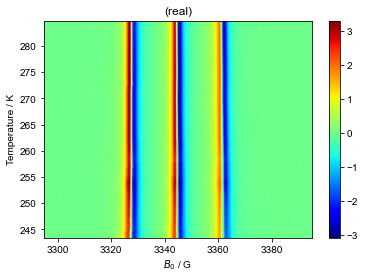

In [12]:
d = find_file("240510_TS_C10_W20_run5.DSC", exp_type="francklab_esr/romana")  # w20
d = d.chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]
d.reorder("Temperature").sort("Temperature")
d.pcolor()

check the field ranges

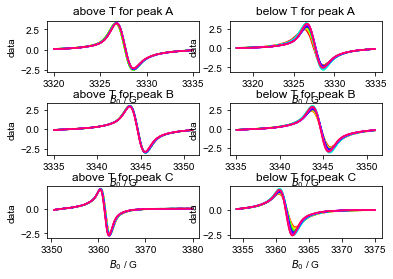

In [13]:
peak_ranges = {
    "above T": {
        "A": (3320, 3335),
        "B": (3335, 3351),
        "C": (3350.5, 3380),
    },
    "below T": {
        "A": (3318, 3335),
        "B": (3335, 3351),
        "C": (3354, 3375),
    },
}
check_ranges(d, peak_ranges)

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

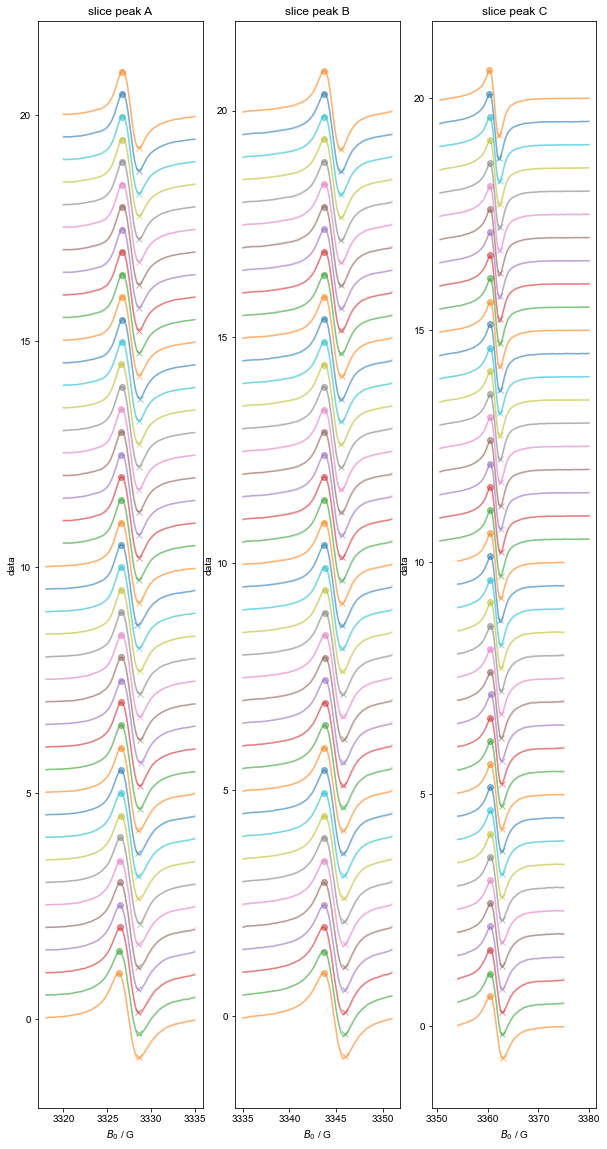

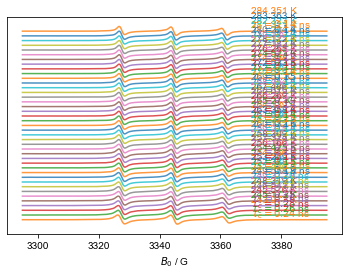

In [14]:
correlation_times_w20 = determine_tau(d, peak_ranges)
arrh_w20 = convert_to_Arrhenius(correlation_times_w20)

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.


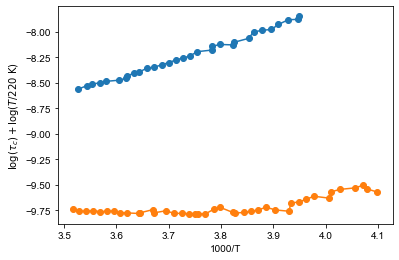

In [13]:
plot(arrh_w3,'o-', label='$w_0=3$')
plot(arrh_w20,'o-', label='$w_0=20$')

## Add data from full simulations

I pursue a similar strategy to add the Multicomponent data to the plot

In [15]:
R1_w3 = {
    "223": 7.670897,
    "253.169": 7.935684,
    "256.653": 7.95353,
    "261.649": 7.975954,
    "268.351": 8.011591,
    "274.489": 8.045357,
    "282.183": 8.10043,
    "293": 7.571283,
}

here's the function -- again, once defined, it can be reused

In [16]:
def dict_R1_to_nddata_tau(d):
    k = np.array([float(j) for j in d.keys()])
    v = np.array(list(d.values()))
    return nddata(1/6*10**-v,[-1],['T']).setaxis('T',k)

In [17]:
simtau_w3 = dict_R1_to_nddata_tau(R1_w3)
arrh_simw3 = convert_to_Arrhenius(simtau_w3)

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.


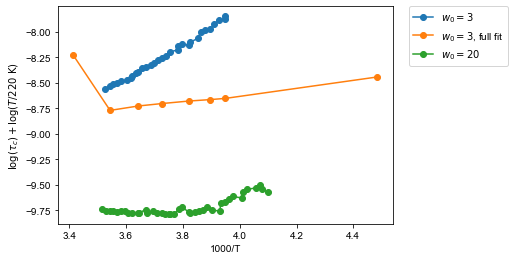

In [18]:
plot(arrh_w3,'o-', label='$w_0=3$')
plot(arrh_simw3,'o-', label='$w_0=3$, full fit')
plot(arrh_w20,'o-', label='$w_0=20$')
fancy_legend()

# RS code -- JF leaving in place for data, etc.

# Pick the Peaks and Calculate the Correlation times
The first cell here only operates over a limited temperature range.

In [18]:
correlation_time_w20 = {}

In [19]:
all_data_w20 = d_w20[
    "Temperature":(None, None)
]  # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl:  ### why with???
    for this_temp in all_data_w20["Temperature"]:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_w20["Temperature":this_temp]
        d /= d.max().item()  ### RS item??? normalize??
        peak_data_w20 = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 230:
            peak_A_range = (3320, 3335)
            peak_B_range = (3335, 3355)
            peak_C_range = (3355, 3375)
        #         elif this_temp >= 250:
        #             peak_A_range = (3320,3358)
        #             peak_B_range = (3358,3382)
        #             peak_C_range = (3376,3403)
        #         else:
        #             peak_A_range = (3320,3358)
        #             peak_B_range = (3358,3382)
        #             peak_C_range = (3382,3406)
        for peak_range, peak_name in [
            (peak_A_range, "A"),
            (peak_B_range, "B"),
            (peak_C_range, "C"),
        ]:
            fl.next(
                f"slice peak {peak_name}"
            )  # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(
                fl.current
            )  # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d[
                "$B_0$":peak_range
            ].spline_lambda()  # create a function that will make a spline curve
            peak = peak_spline_fn(
                linspace(*tuple(peak_range + (500,)))
            )  # make a smooth, high-res curve of our peak, using the spline
            plot(peak, c=this_color, alpha=0.2)
            peak = d["$B_0$":peak_range].spline_lambda(s_multiplier=1e-4)(
                linspace(*tuple(peak_range + (500,)))
            )
            plot(
                peak, c=this_color, alpha=0.5
            )  # overwrite with a smoothed one
            max_B0 = (
                peak.C.argmax().item()
            )  # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()[
                "$B_0$"
            ]  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_w20[peak_name + "max"] = peak[
                "$B_0$":max_B0
            ].item()  # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_w20[peak_name + "min"] = peak["$B_0$":min_B0].item()
            peak_data_w20[
                peak_name + "maxB0"
            ] = max_B0  # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_w20[peak_name + "minB0"] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(
                peak_data_w20[peak_name + "maxB0"],
                peak_data_w20[peak_name + "max"],
                "o",
                c=this_color,
                alpha=0.5,
            )
            plot(
                peak_data_w20[peak_name + "minB0"],
                peak_data_w20[peak_name + "min"],
                "x",
                c=this_color,
                alpha=0.5,
            )
            # }}}
        fl.next(
            "pub_fig", figsize=(10, 10 / (1 + sqrt(5)) * 2), dpi=400
        )  ## use golden ratio for figure size
        fl.plot(
            d + x_counter, alpha=0.8, color=this_color, human_units=False
        )  ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_w20 = eval(
            "6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",
            {"sqrt": sqrt},
            peak_data_w20,
        )
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is", tau_c)
        correlation_time_w20[label_str] = tau_c_w20
        plt.gca().text(
            3370,
            x_counter,
            label_str + f" K\n$\\tau_c={tau_c_w20/1e-9:0.1f}$ ns",
            transform=plt.gca().transData,
            va="bottom",
            ha="left",
            color=this_color,
        )
        x_counter += 1.5
        # xlim(3375,3550)
        j_counter += 1
    fl.next("pub_fig")
    plt.title("")
    plt.ylabel("")
    plt.gca().tick_params(
        left=False,
        bottom=True,
        right=False,
        top=False,
        labelleft=False,
        labelbottom=True,
        labelright=False,
    )

NameError: name 'd_w20' is not defined

In [ ]:
correlation_time_w20

In [ ]:
temp_w20 = np.array([float(j) for j in correlation_time_w20.keys()])
tau_w20 = np.array(list(correlation_time_w20.values()))

Tau caculation

In [ ]:
figure(dpi=300, figsize=(6, 4))
plot(
    temp_w3,
    tau_w3 / 1e-9,
    linestyle="-",
    marker="o",
    label=r"$\tau_c$ for $w_0=3$",
)
plot(
    temp_w20,
    tau_w20 / 1e-9,
    linestyle="-",
    marker="o",
    label=r"$\tau_c$ for $w_0=20$",
)
legend()
xlabel("Temperature (K)")
ylabel("Correlation Time (ns)")
title("Correlation Time from linewidth for 20 mM TEMPO-SO$_4$ in dodecane")
show()

Arrhenius

In [ ]:
figure(dpi=300, figsize=(6, 4))
plot(
    1000 / temp_w3,
    log10(tau_w3 * temp_w3),
    linestyle="-",
    marker="o",
    label=r"for $w_0=3$",
)
plot(
    1000 / temp_w20,
    log10(tau_w20 * temp_w20),
    linestyle="-",
    marker="o",
    label=r"for $w_0=20$",
)
legend()
# xlim(2.9,4.1)
xlabel(r"1000/Temperature $(K^{-1})$")
ylabel(r"$logT+ log(\tau_c)$")
title("Arrhenius temperature dependance from linewidth")
show()

# Correlation time from Multicomponent fitting

Sample name: 	20 mM TEMPO-SO4 in Dodecane $w_0=3$

In [ ]:
R1_w3 = {
    "223": 7.670897,
    "253.169": 7.935684,
    "256.653": 7.95353,
    "261.649": 7.975954,
    "268.351": 8.011591,
    "274.489": 8.045357,
    "282.183": 8.10043,
    "293": 7.571283,
}

Sample name: 	20 mM TEMPO-SO4 in Dodecane $w_0=20$

In [ ]:
R1_w20 = {
    "243.977": 8.161657,
    "249.372": 8.161175,
    "254.425": 8.158947,
    "261.322": 8.161238,
    "270.679": 8.160712,
    "283.363": 8.157241,
}

In [ ]:
temp_fit_w3 = np.array([float(j) for j in R1_w3.keys()])
R1_fit_w3 = np.array(list(R1_w3.values()))
temp_fit_w20 = np.array([float(j) for j in R1_w20.keys()])
R1_fit_w20 = np.array(list(R1_w20.values()))

In [ ]:
tau_fit_w3 = 0.5241 / (pi * 10**R1_fit_w3)
tau_fit_w20 = 0.5241 / (pi * 10**R1_fit_w20)

In [ ]:
print(tau_fit_w3)
print(tau_fit_w20)

Tau plot from fitting

In [ ]:
figure(dpi=300, figsize=(6, 4))
plot(
    temp_fit_w3,
    tau_fit_w3 / 1e-9,
    linestyle="-",
    marker="o",
    label=r"$\tau_c$ for $w_0=3$",
)
plot(
    temp_fit_w20,
    tau_fit_w20 / 1e-9,
    linestyle="-",
    marker="o",
    label=r"$\tau_c$ for $w_0=20$",
)
legend()
xlabel("Temperature (K)")
ylabel("Correlation Time (ns)")
title("Correlation Time from fitting for 20 mM TEMPO-SO$_4$ in dodecane")
show()

Arrhenius Temperature dependance

In [ ]:
figure(dpi=300, figsize=(6, 5))

from linewidth

In [ ]:
plot(
    1000 / temp_w3,
    log10(tau_w3 * temp_w3),
    linestyle="-",
    label=r"for $w_0=3$ from linwidth",
)
plot(
    1000 / temp_w20,
    log10(tau_w20 * temp_w20),
    linestyle="-",
    label=r"for $w_0=20$ from linewidth",
)

from fitting

In [ ]:
plot(
    1000 / temp_fit_w3,
    log10(tau_fit_w3 * temp_fit_w3),
    marker="o",
    linestyle="",
    label=r"for $w_0=3$ from fitting",
)
plot(
    1000 / temp_fit_w20,
    log10(tau_fit_w20 * temp_fit_w20),
    marker="x",
    linestyle="",
    label=r"for $w_0=20$ from fitting",
)
legend()
xlabel(r"1000/Temperature $(K^{-1})$")
ylabel(r"$logT+ log(\tau_c)$")
title("Arrhenius temperature dependance for 20 mM TEMPO-SO$_4$ in dodecane")
show()